# Projeto ArPrev — 04 · Comparativo das Famílias de Árvores e Latência
**ArPrev — Foco na Antecipação de Condições Inadequadas**  
*Mogi das Cruzes / SP — Campus UBC | Trilha B (Qualidade do Ar)*

Este notebook documenta o experimento comparativo exigido pelo Plano de Ensino da disciplina, analisando três famílias baseadas em árvores:
1. **Árvore de Decisão Única (CART):** modelo simples e interpretável, porém com alta variância e suscetível a *overfitting*.
2. **Random Forest (Bagging):** combinação de 300 árvores com amostragem aleatória de dados e *features*, reduzindo variância e maximizando o *Recall* (Modelo Escolhido).
3. **XGBoost (Boosting):** construção sequencial corrigindo resíduos da iteração anterior, maximizando a Precisão e F1.

Além da eficácia preditiva (*Recall*, Precisão, F1-Score, Falsos Negativos), analisamos o **tempo de treino** e a **latência de predição** em milissegundos.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# Caminhos dos relatórios e figuras gerados por src/modelagem/Experimento_Arvores_Artigo.py
RELATORIO_MODELOS = Path("../reports/modeling/artigo_comparativo_modelos.csv")
RELATORIO_PROFUNDIDADE = Path("../reports/modeling/artigo_profundidade_arvore.csv")
PASTA_FIGURAS = Path("../reports/figures/")

# Fallback caso executado a partir da raiz do repositório
if not RELATORIO_MODELOS.exists():
    RELATORIO_MODELOS = Path("reports/modeling/artigo_comparativo_modelos.csv")
    RELATORIO_PROFUNDIDADE = Path("reports/modeling/artigo_profundidade_arvore.csv")
    PASTA_FIGURAS = Path("reports/figures/")

## 1. Tabela Comparativa de Desempenho e Latência no Holdout (2025–2026)

O teste final (*holdout*) contém 14.592 horas sequenciais com **161 episódios reais de IQAr > 100**. O limiar de decisão operacional adotado é **0,30**.

In [2]:
df_modelos = pd.read_csv(RELATORIO_MODELOS)

# Filtra e formata o teste final (Holdout 2025-2026)
colunas_map = {
    'modelo': 'Modelo',
    'recall_classe_1': 'Recall',
    'precisao_classe_1': 'Precisão',
    'f1_classe_1': 'F1-Score',
    'tp': 'TP',
    'fp': 'FP',
    'fn': 'FN',
    'tempo_treino_s': 'Treino (s)',
    'tempo_predicao_ms': 'Latência Lote (ms)',
    'latencia_por_amostra_ms': 'Latência / Amostra (ms)'
}

df_holdout = df_modelos[df_modelos['fold'] == 'holdout_2025_2026'][list(colunas_map.keys())].rename(columns=colunas_map)

# Formatação percentual das métricas
df_holdout['Recall'] = (df_holdout['Recall'] * 100).round(2).astype(str) + '%'
df_holdout['Precisão'] = (df_holdout['Precisão'] * 100).round(2).astype(str) + '%'
df_holdout['F1-Score'] = (df_holdout['F1-Score'] * 100).round(2).astype(str) + '%'
df_holdout['Treino (s)'] = df_holdout['Treino (s)'].round(3)
df_holdout['Latência Lote (ms)'] = df_holdout['Latência Lote (ms)'].round(2)
df_holdout['Latência / Amostra (ms)'] = df_holdout['Latência / Amostra (ms)'].round(4)

display(df_holdout)

,Modelo,Recall,Precisão,F1-Score,TP,FP,FN,Treino (s),Latência Lote (ms),Latência / Amostra (ms)
7,persistencia_iqar_atual,78.88%,78.88%,78.88%,127,34,34,0.000,0.90,0.0001
8,dummy_prior,0.0%,0.0%,0.0%,0,0,161,0.002,0.57,0.0000
9,gaussian_naive_bayes,100.0%,34.92%,51.77%,161,300,0,0.068,20.15,0.0014
10,regressao_logistica_balanced,100.0%,73.18%,84.51%,161,59,0,0.106,13.15,0.0009
11,arvore_decisao_cart,86.34%,80.81%,83.48%,139,33,22,0.115,11.48,0.0008
12,random_forest_balanced,98.14%,78.22%,87.05%,158,44,3,1.639,106.66,0.0073
13,xgboost_balanced,96.27%,88.57%,92.26%,155,20,6,0.855,38.28,0.0026


### Principais Conclusões Científicas:
- **Árvore de Decisão CART (`arvore_decisao_cart`):** Recall = 86,34% e **22 Falsos Negativos**. Sofreu grande perda de generalização em anos secos/quentes como 2025.
- **XGBoost (`xgboost_balanced`):** Maior Precisão (88,57%) e maior F1 (92,26%), porém deixou passar **6 alertas críticos** (Recall = 96,27%).
- **Random Forest (`random_forest_balanced` — Modelo Escolhido):** **Maior Recall (98,14%)**, deixando escapar apenas **3 alertas** em quase dois anos (14.592 horas), com latência por consulta de frações de milissegundo.

## 2. Evidência Empírica de Overfitting da Árvore Única (Profundidade)

Variação de `max_depth` de 1 até sem limite (19 níveis). Mostra como a partir de `max_depth > 10`, o F1 de treino atinge 1,0000 enquanto os Falsos Negativos na validação saltam de 1 para 7.

,max_depth_config,profundidade_real,n_folhas,recall_treino,f1_treino,recall_validacao,precisao_validacao,f1_validacao,fp_validacao,fn_validacao
0,1,1,2,0.9785,0.6934,1.0000,0.4381,0.6093,59,0
1,2,2,4,1.0000,0.6787,1.0000,0.4259,0.5974,62,0
2,3,3,8,1.0000,0.8035,1.0000,0.5542,0.7132,37,0
3,4,4,12,1.0000,0.8563,0.9783,0.6000,0.7438,30,1
4,5,5,18,1.0000,0.9275,0.9783,0.8491,0.9091,8,1
5,6,6,24,1.0000,0.9406,0.9565,0.8302,0.8889,9,2
6,8,8,38,1.0000,0.9708,0.9783,0.9375,0.9574,3,1
7,10,10,52,1.0000,0.9810,0.9565,0.9362,0.9462,3,2
8,12,12,61,1.0000,0.9880,0.8478,0.9286,0.8864,3,7
9,15,15,73,1.0000,0.9957,0.8478,0.9286,0.8864,3,7


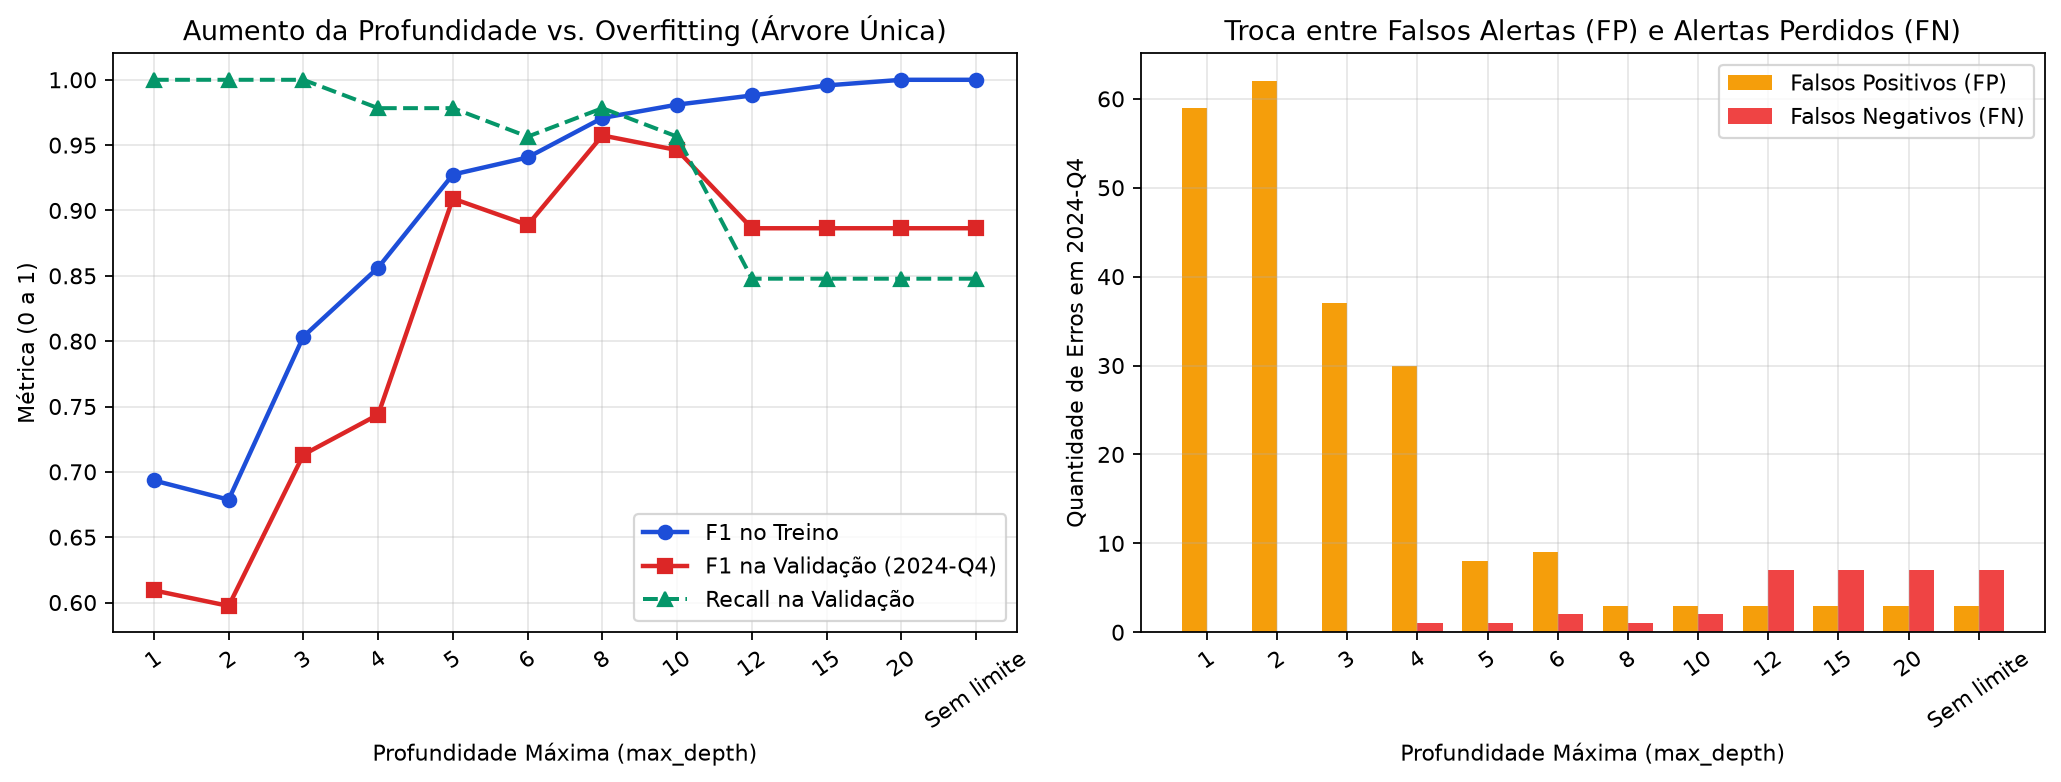

In [3]:
df_prof = pd.read_csv(RELATORIO_PROFUNDIDADE)
display(df_prof.head(10))

fig_overfit = PASTA_FIGURAS / 'fig_overfitting_profundidade.png'
if fig_overfit.exists():
    display(Image(filename=str(fig_overfit)))

## 3. Visualizações Didáticas do Estudo Comparativo

Abaixo estão as figuras didáticas geradas e exportadas para o [Artigo Técnico no GitHub Pages](https://diogogomesb.github.io/Ciencia-de-Dados-e-Aprendizagem-de-Maquina/) e o repositório.

=== Comparativo de Recall, Precisão e F1 no Holdout (2025-2026) ===


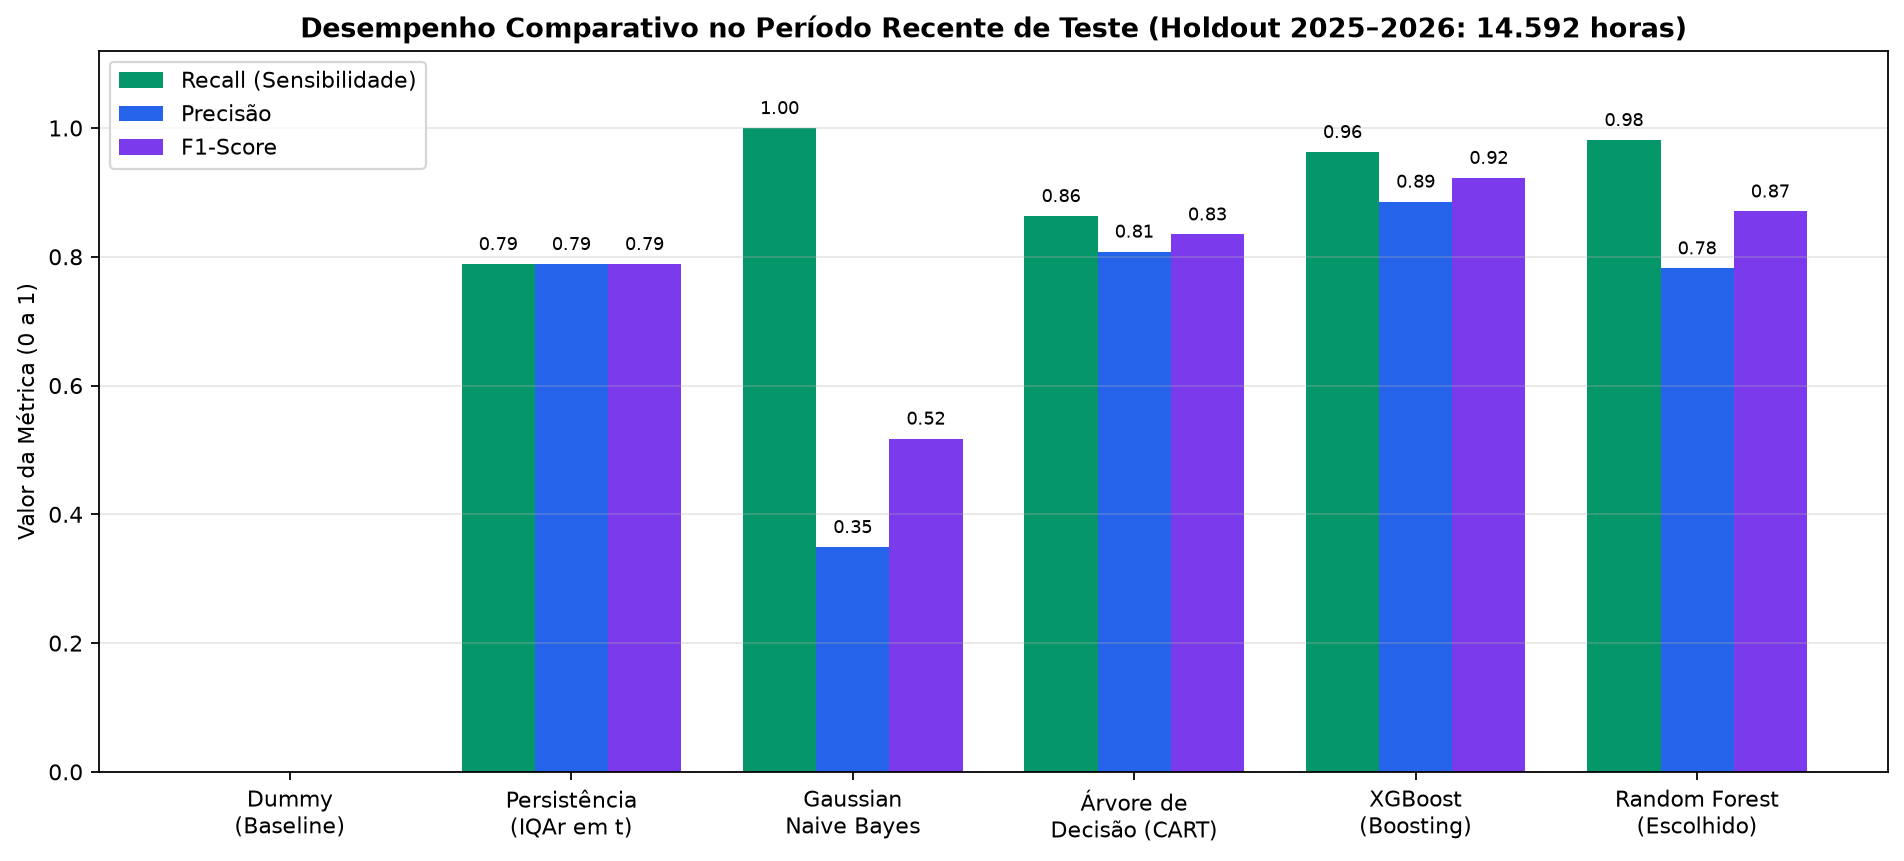

=== Matrizes de Confusão: CART vs. Random Forest vs. XGBoost ===


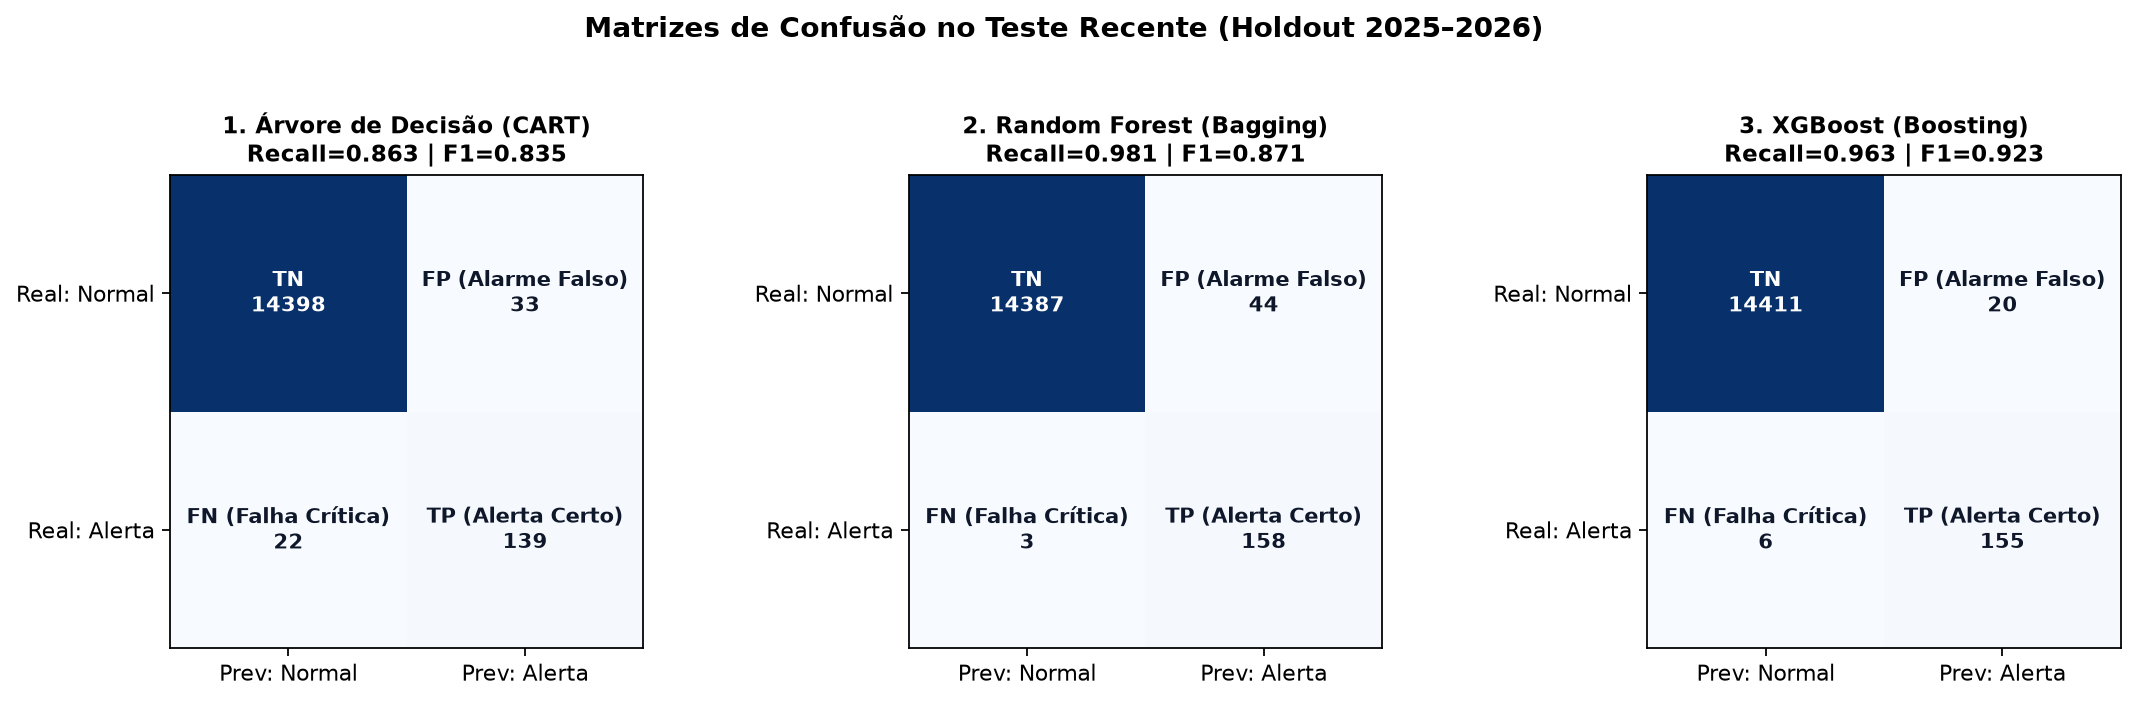

=== Árvore de Decisão Rasa (Profundidade 3) para Interpretabilidade ===


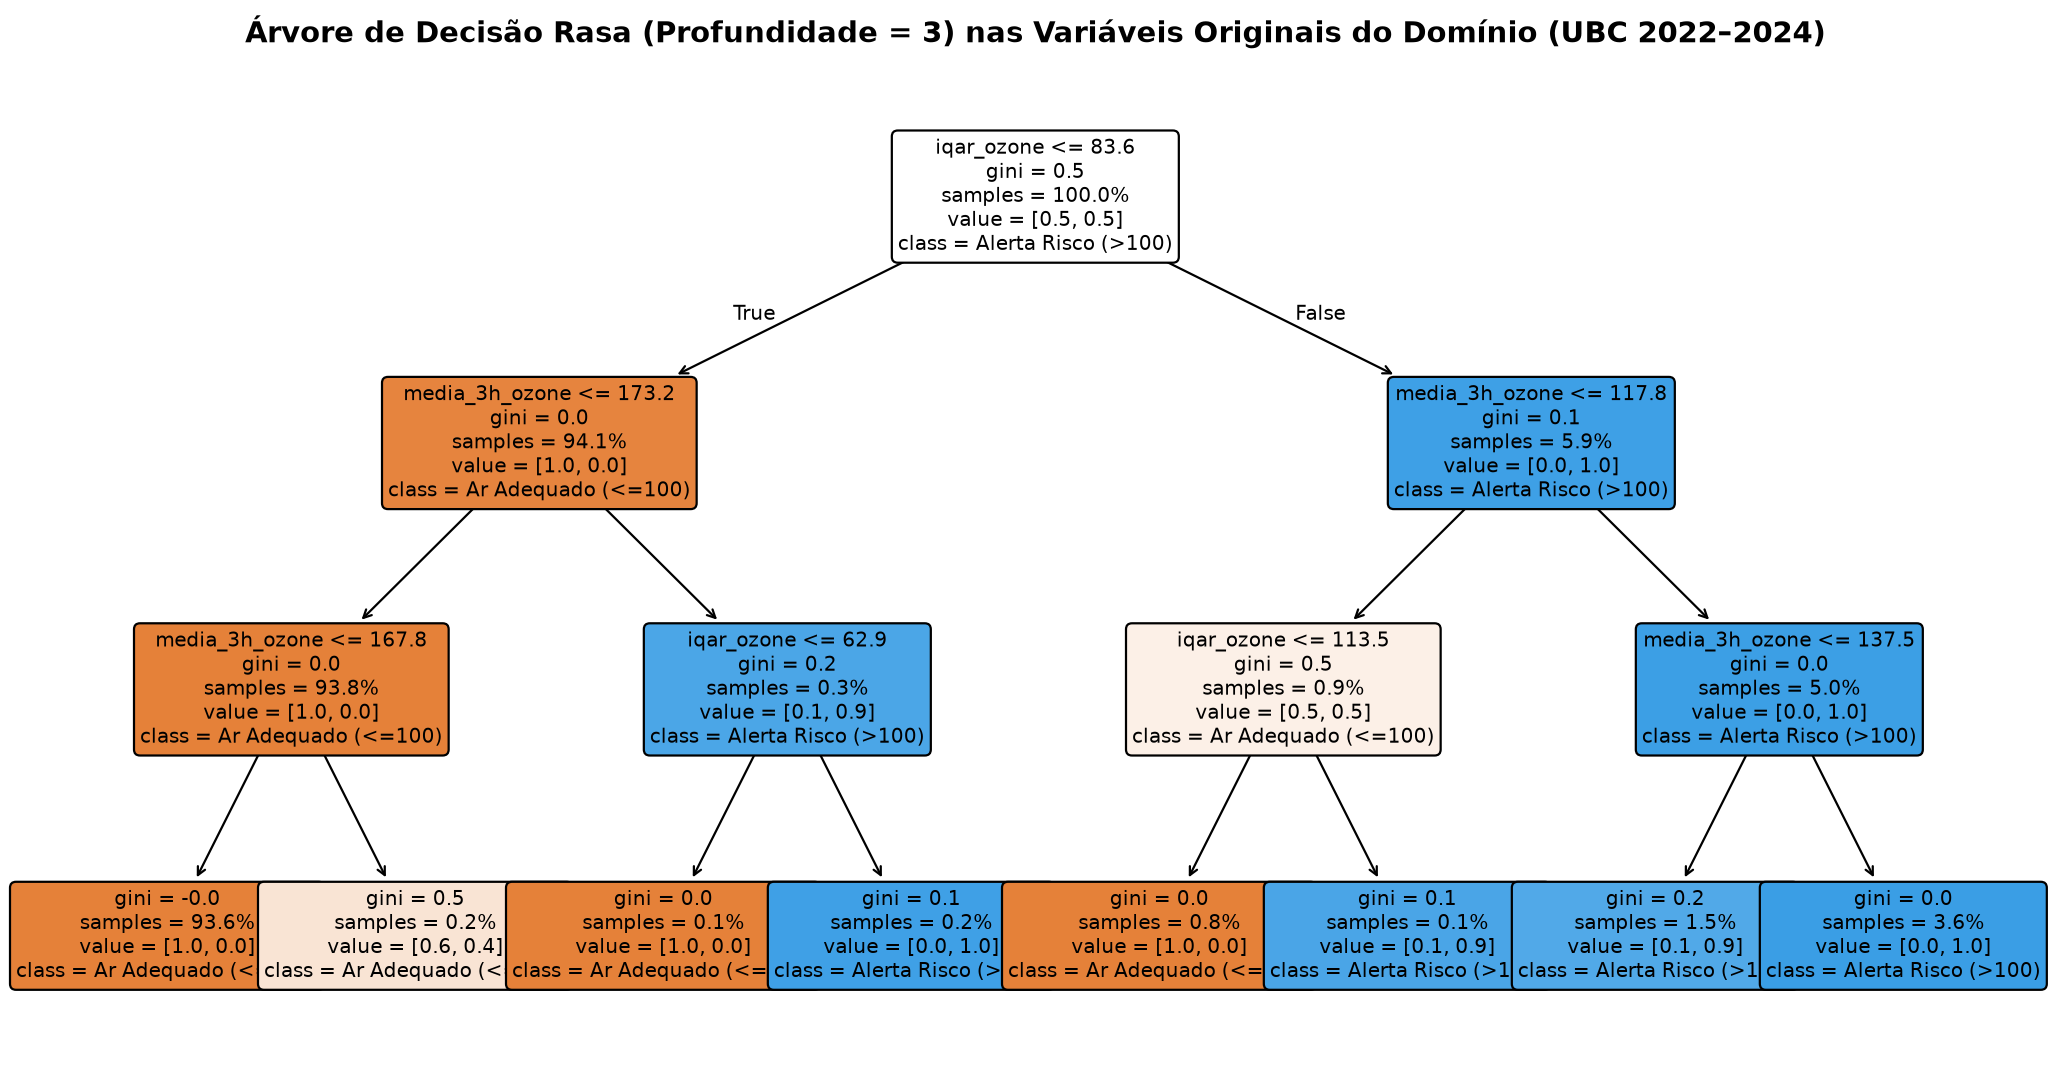

=== Importância de Features (Gini vs. Gain) e Latência de Predição ===


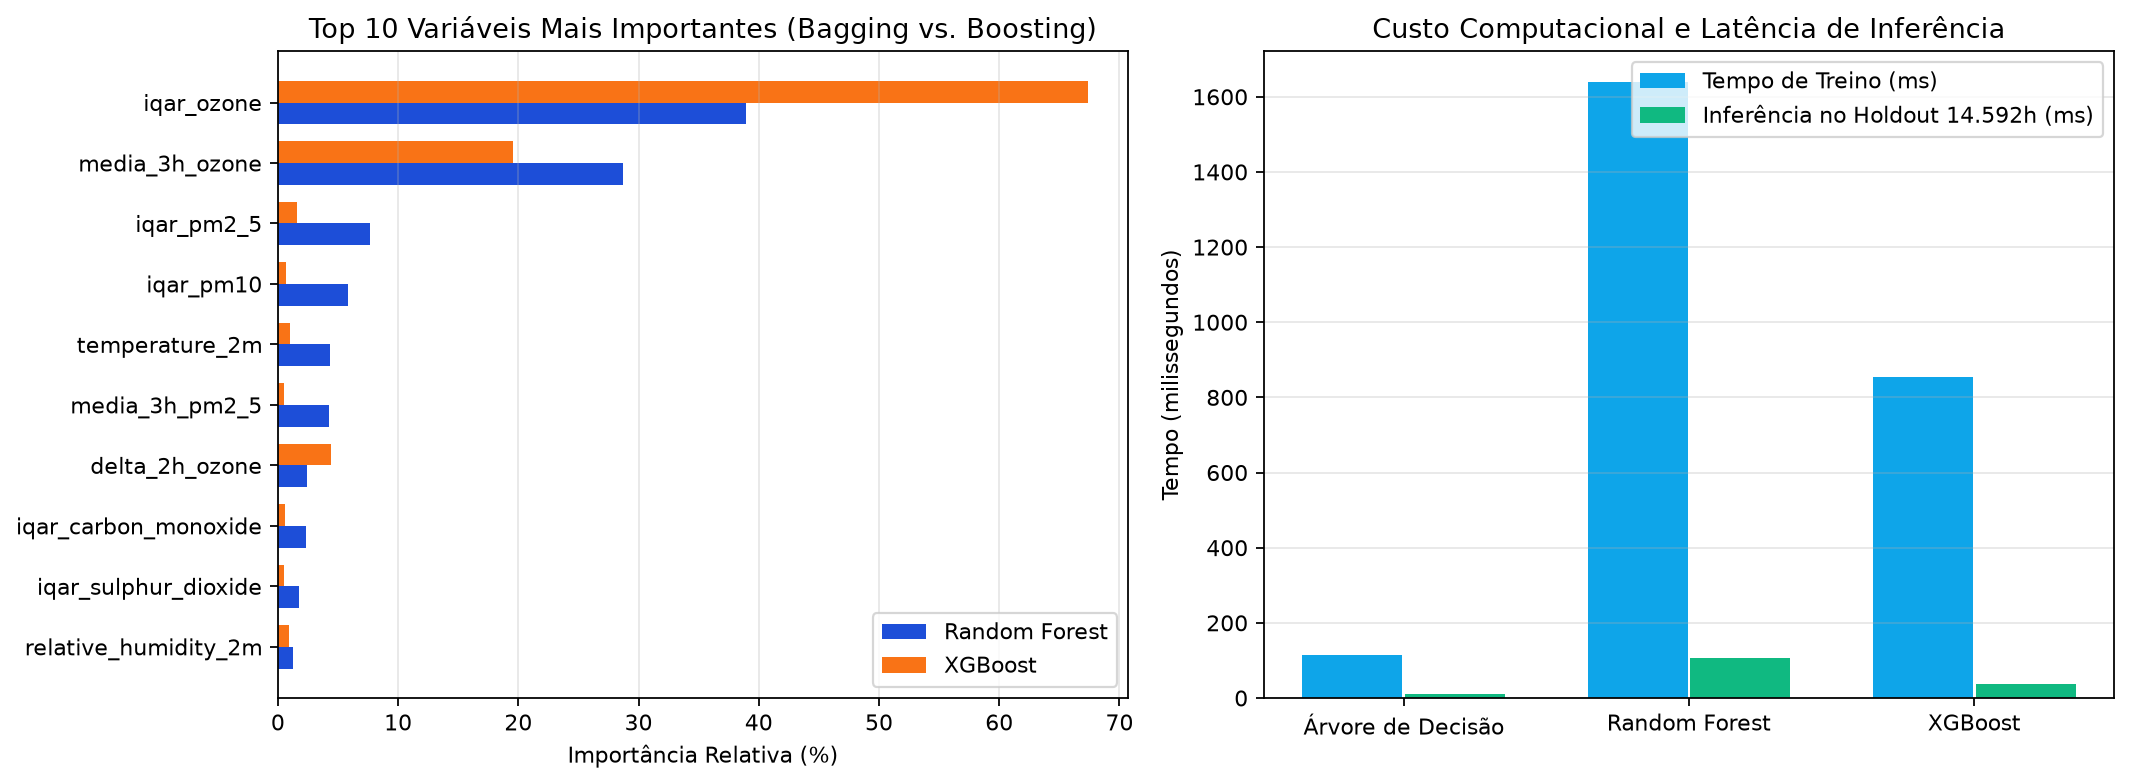

In [4]:
figuras = [
    ('fig_comparacao_modelos_metricas.png', 'Comparativo de Recall, Precisão e F1 no Holdout (2025-2026)'),
    ('fig_matriz_confusao_3_arvores.png', 'Matrizes de Confusão: CART vs. Random Forest vs. XGBoost'),
    ('fig_arvore_decisao_rasa.png', 'Árvore de Decisão Rasa (Profundidade 3) para Interpretabilidade'),
    ('fig_importancia_e_latencia.png', 'Importância de Features (Gini vs. Gain) e Latência de Predição')
]

for fig_name, titulo in figuras:
    caminho = PASTA_FIGURAS / fig_name
    if caminho.exists():
        print(f'=== {titulo} ===')
        display(Image(filename=str(caminho)))

## 4. Como Executar Novamente o Experimento Completo

Para reproduzir os números, treinar os modelos e regerar as figuras:

```powershell
.\.venv\Scripts\python.exe -m src.modelagem.Experimento_Arvores_Artigo
```

Para interagir com os modelos ao vivo:

```powershell
.\.venv\Scripts\streamlit.exe run streamlit_app.py
```